# Finding Hidden Groups in the Karate Club Network
### DSC212 – Graph Theory Assignment: Modularity and Eigenvectors

In this notebook we take a network of 34 karate club members (who is friends with whom) and try to find the groups hiding inside it, using **modularity** and **eigenvectors**.

The notebook follows the five tasks of the assignment:
- **Task 1:** Recursive spectral modularity partitioning
- **Task 2:** Graph visualizations across each split
- **Task 3:** Node metrics after each split
- **Task 4:** Evolution of each metric across iterations
- **Task 5:** Discussion

In [10]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

## Setup: Loading the Network and Building the Modularity Matrix B

`A` is the adjacency matrix (1 if two people are friends, 0 if not). `k` holds the number of friends each person has, and `m` is the total number of friendships.

The modularity matrix is  **B = A − (k kᵀ) / (2m)**, which means *real friendships minus the friendships we would expect by chance*.

In [11]:
G = nx.karate_club_graph()          # the 34-person network
n = G.number_of_nodes()             # number of people
m = G.number_of_edges()             # number of friendships

A = nx.to_numpy_array(G, weight=None)   # adjacency matrix (0/1)
k = A.sum(axis=1)                       # number of friends of each person

B = A - np.outer(k, k) / (2 * m)        # modularity matrix

print("People:", n, " Friendships:", m)

People: 34  Friendships: 78


## Splitting One Group Using the Leading Eigenvector (Task 1, Part A)

To split a group of people:
1. Take the part of `B` that belongs to those people.
2. Find its biggest eigenvalue and the matching eigenvector.
3. If the biggest eigenvalue is **not positive**, stop: this group can't be split any better.
4. Otherwise, people with a **positive** eigenvector entry go to group 1 and everyone else goes to group 2.

We also need a function to compute the modularity score `Q` of a set of groups.

In [12]:
def split_group(group):
    # Try to split a list of people into two. Returns (group1, group2), or None if no split.
    group = np.array(group)
    B_small = B[np.ix_(group, group)]            # the part of B for these people

    values, vectors = np.linalg.eigh(B_small)    # eigenvalues (smallest to largest) and eigenvectors
    biggest_value = values[-1]
    biggest_vector = vectors[:, -1]

    if biggest_value <= 1e-9:                    # not positive -> do not split
        return None

    group1 = group[biggest_vector > 0]           # positive entries
    group2 = group[biggest_vector <= 0]          # the rest
    if len(group1) == 0 or len(group2) == 0:     # everybody on one side -> no real split
        return None
    return [int(p) for p in group1], [int(p) for p in group2]


def modularity(groups):
    # Modularity Q: add up B for every pair of people in the same group, then divide by 2m.
    total = 0
    for g in groups:
        total += B[np.ix_(g, g)].sum()
    return total / (2 * m)

## Recursive Spectral Modularity Partitioning (Task 1, Part B)

We start with everybody in one group. We split it, then try to split each new group, and so on. We save the list of groups after every split so we can draw and measure each step later.

In [13]:
groups = [list(range(n))]                   # start: everyone in one group
steps = [[g[:] for g in groups]]            # steps[0] = before any split
scores = [modularity(groups)]               # modularity after each step

to_try = [0]                                # positions of groups we still want to try to split
while to_try:
    i = to_try.pop(0)
    result = split_group(groups[i])
    if result is None:
        continue                            # this group cannot be split
    groups[i] = result[0]                   # group 1 replaces the old group
    groups.append(result[1])                # group 2 is added at the end
    to_try += [i, len(groups) - 1]          # try to split both new groups later

    steps.append([g[:] for g in groups])
    scores.append(modularity(groups))

for s in range(len(steps)):
    print(f"After split {s}: {len(steps[s])} group(s), modularity Q = {scores[s]:.3f}")

print()
for i, g in enumerate(groups):
    print(f"Final group {i + 1}: {sorted(g)}")

After split 0: 1 group(s), modularity Q = -0.000
After split 1: 2 group(s), modularity Q = 0.371
After split 2: 3 group(s), modularity Q = 0.390
After split 3: 4 group(s), modularity Q = 0.408
After split 4: 5 group(s), modularity Q = 0.409

Final group 1: [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
Final group 2: [24, 25, 27, 28, 31]
Final group 3: [11]
Final group 4: [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
Final group 5: [4, 5, 6, 10, 16]


### Verifying the Partitioning Result (Task 1 Check)

NetworkX can compute modularity too, so we can check that our answer is right. We can also compare our **first split** with the two real groups the club broke into (stored in the graph as `club`).

In [14]:
# 1. compare our modularity with NetworkX
print("Our Q     :", round(scores[-1], 4))
print("NetworkX Q:", round(nx.community.modularity(G, [set(g) for g in groups], weight=None), 4))

# 2. compare the first split with the real split
first_split = steps[1]
real_hi = {i for i in range(n) if G.nodes[i]["club"] == "Mr. Hi"}
side_a = set(first_split[0])
matches = len(side_a & real_hi) + len(set(first_split[1]) - real_hi)
matches = max(matches, n - matches)   # the two sides could be named the other way round
print(f"\nFirst split agrees with the real split for {matches} of {n} people")

Our Q     : 0.4094
NetworkX Q: 0.4094

First split agrees with the real split for 33 of 34 people


## Graph Visualizations Across Each Split (Task 2)

Each group gets its own colour. We use the **same layout** every time, so nodes stay in the same place and only the colours change.

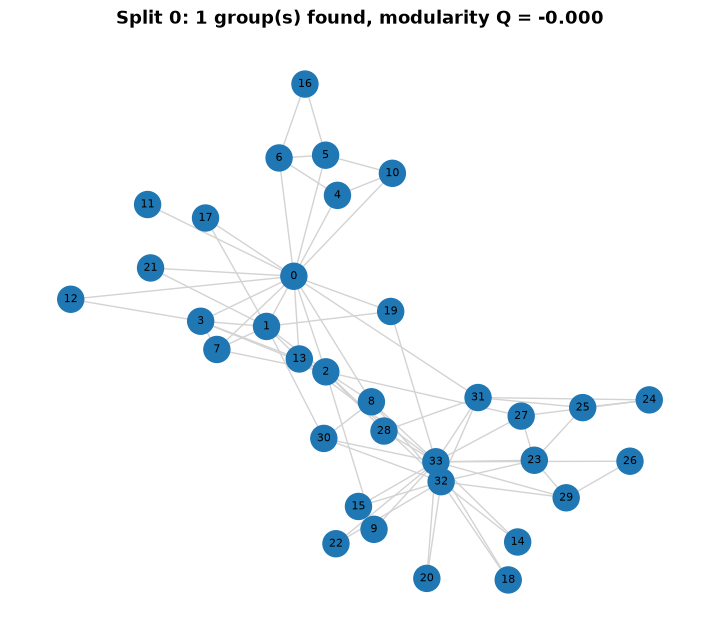

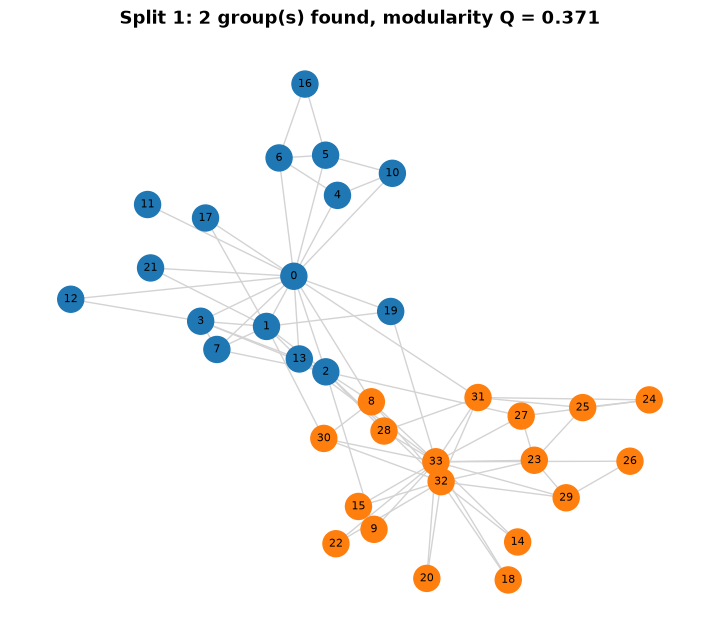

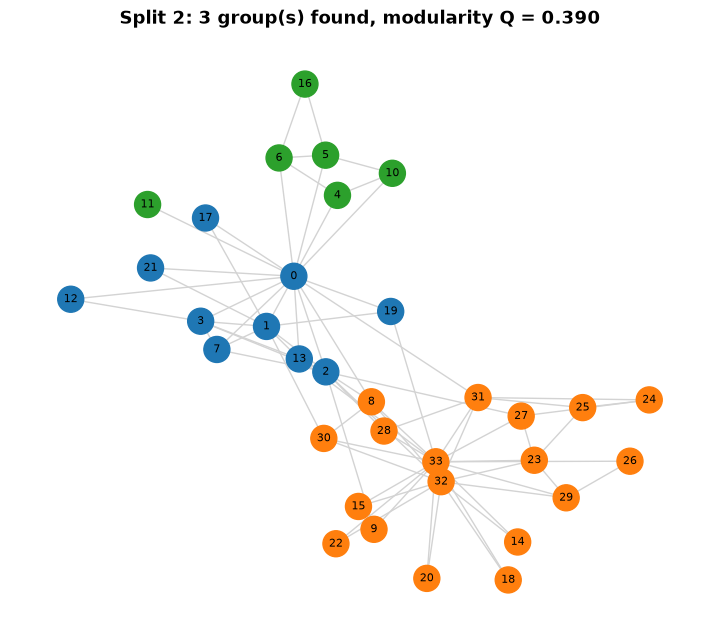

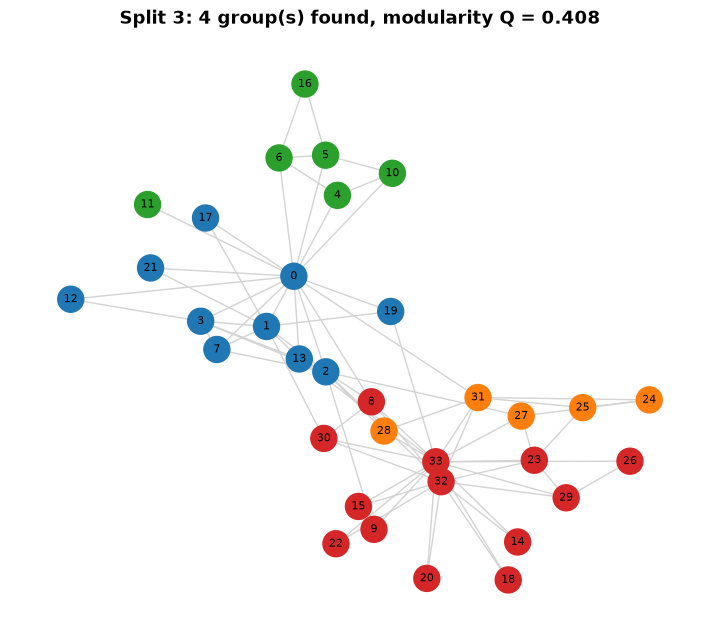

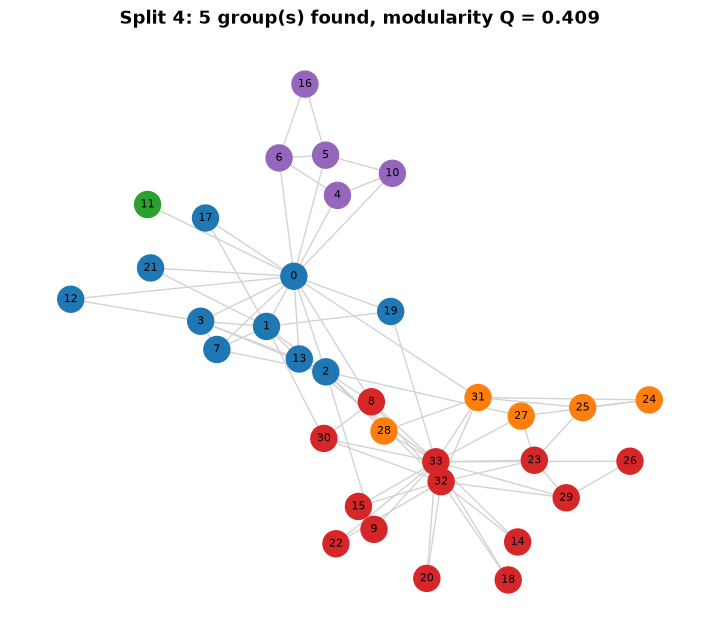

In [15]:
pos = nx.spring_layout(G, seed=42)          # fixed positions for every picture
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"]

for s, state in enumerate(steps):
    node_color = {}
    for i, g in enumerate(state):
        for person in g:
            node_color[person] = colors[i]

    plt.figure(figsize=(7, 6))
    nx.draw(G, pos, with_labels=True, node_size=350, font_size=8,
            node_color=[node_color[v] for v in G.nodes], edge_color="lightgray")
    plt.title(f"Split {s}: {len(state)} group(s) found, modularity Q = {scores[s]:.3f}", fontsize=13, fontweight="bold")
    plt.show()

## Node Metrics After Each Split (Task 3)

After each split we calculate four numbers for every person:

| Measure | In plain words |
|---|---|
| Degree centrality | how many friends the person has |
| Betweenness centrality | how often the person lies on the shortest path between two others (a "bridge") |
| Closeness centrality | how quickly the person can reach everyone else |
| Clustering coefficient | how many of the person's friends are also friends with each other |

**Note:** if we measured the whole graph every time, the numbers would never change, because splitting only changes the colours. So we measure each person **inside their own group** (using only the people in that group).

In [16]:
measures = {
    "Degree centrality": nx.degree_centrality,
    "Betweenness centrality": nx.betweenness_centrality,
    "Closeness centrality": nx.closeness_centrality,
    "Clustering coefficient": nx.clustering,
}

# results[name][s][person] = value of that measure for that person after split s
results = {name: [] for name in measures}

for state in steps:
    for name, function in measures.items():
        values = {}
        for g in state:
            if len(g) == 1:
                values[g[0]] = 0.0                  # a lone person has nothing to measure
            else:
                values.update(function(G.subgraph(g)))   # measure inside the group only
        results[name].append(values)

# Look at the five highest nodes for each measure, before and after all splits
for name in measures:
    first = sorted(results[name][0].items(), key=lambda x: -x[1])[:5]
    last = sorted(results[name][-1].items(), key=lambda x: -x[1])[:5]
    print(name)
    print("  whole graph :", [(p, round(v, 2)) for p, v in first])
    print("  final groups:", [(p, round(v, 2)) for p, v in last])

Degree centrality
  whole graph : [(33, 0.52), (0, 0.48), (32, 0.36), (2, 0.3), (1, 0.27)]
  final groups: [(0, 1.0), (33, 1.0), (1, 0.89), (32, 0.83), (24, 0.75)]
Betweenness centrality
  whole graph : [(0, 0.44), (33, 0.3), (32, 0.15), (2, 0.14), (31, 0.14)]
  final groups: [(33, 0.55), (24, 0.5), (31, 0.5), (0, 0.35), (32, 0.26)]
Closeness centrality
  whole graph : [(0, 0.57), (2, 0.56), (33, 0.55), (31, 0.54), (8, 0.52)]
  final groups: [(0, 1.0), (33, 1.0), (1, 0.9), (32, 0.86), (24, 0.8)]
Clustering coefficient
  whole graph : [(7, 1.0), (12, 1.0), (14, 1.0), (15, 1.0), (16, 1.0)]
  final groups: [(7, 1.0), (12, 1.0), (13, 1.0), (17, 1.0), (19, 1.0)]


## Evolution of Each Metric Across Iterations (Task 4)

Every one of the 34 people has a line. The **thin grey lines** are all the other people. The **coloured lines** highlight the five who matter most in the discussion: **0** and **33** (the two leaders), **32**, **1** and **24**. The dotted black line is the **average over all 34 people**.

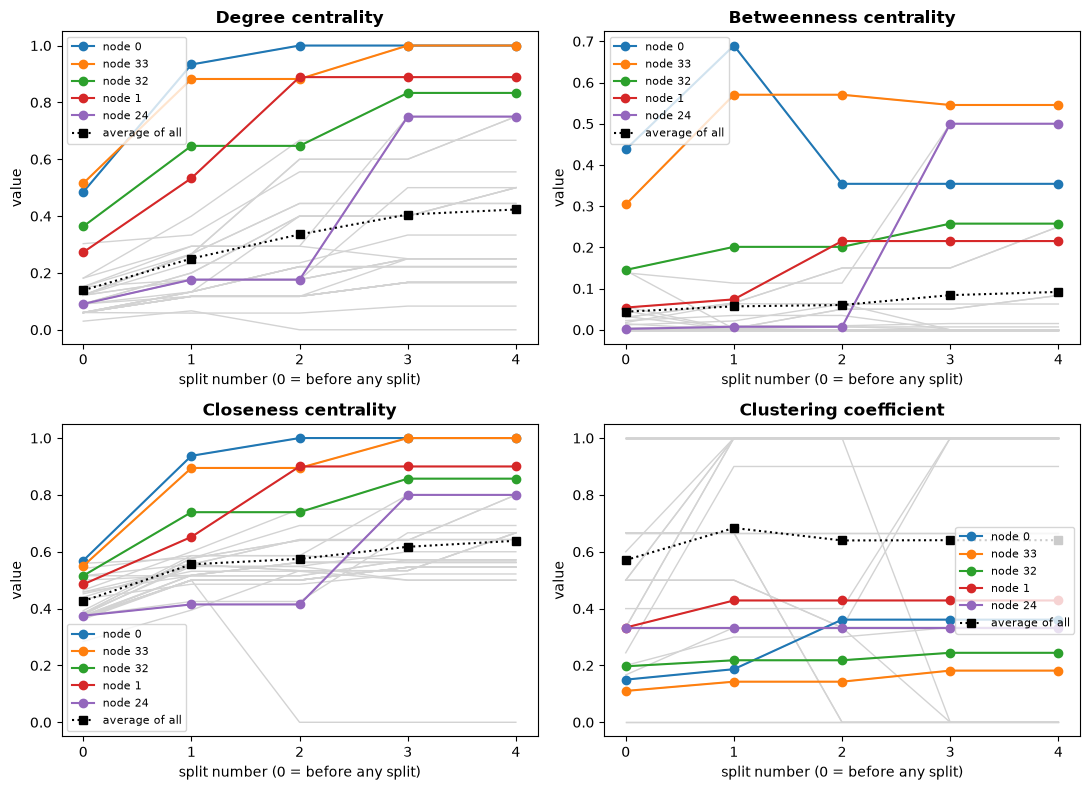

In [17]:
people = [0, 33, 32, 1, 24]
x = list(range(len(steps)))

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, name in zip(axes.ravel(), measures):
    for p in range(n):                      # every node gets a thin grey line
        ax.plot(x, [results[name][s][p] for s in x], color="lightgray", linewidth=1)
    for p in people:                        # highlighted nodes on top
        ax.plot(x, [results[name][s][p] for s in x], marker="o", label=f"node {p}")
    average = [np.mean(list(results[name][s].values())) for s in x]
    ax.plot(x, average, "k:", marker="s", label="average of all")
    ax.set_title(name, fontsize=12, fontweight="bold")
    ax.set_xlabel("split number (0 = before any split)")
    ax.set_ylabel("value")
    ax.set_xticks(x)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Discussion: Central Nodes and the Effect of Community Structure (Task 5)

**1. What the algorithm found**

 The very first split cut the club into 16 and 18 people, and this matched the real split of the club for 33 out of 34 members. Only node 8 ended up on the "wrong" side. That is quite impressive, because the algorithm only knew who was friends with whom; it was never told about the real argument that split the club. Node 8 has friends in both camps, so it makes sense that he was hard to place. After more splits we ended with 5 groups and a modularity of about 0.41. The last split only separated node 11, who has a single friend (node 0), so that step is more of a quirk than a meaningful community.

**2. Which people stay important?**

 Nodes **0 and 33** (the two leaders) and node **32** were in the top 5 for degree, betweenness and closeness after every single split. No matter how we cut the network, these people were at the centre of their groups. Node 0 and node 33 even end up with a degree and closeness of 1.0, meaning that each of them is friends with everybody else in their final group.

**3. Some people matter more inside a small group**

 Nodes 31 and 24 look ordinary in the whole network (betweenness 0.14 and 0.002), but once they sit in the small group {24, 25, 27, 28, 31} their betweenness jumps to 0.5, because they connect the other members of that group. On the other hand, node 2 starts with high closeness in the full graph, but after the splits its betweenness drops close to zero, because nodes 0 and 1 handle most of the paths in its group. So being central in the whole network is not the same as being central in your own group.

**4. How the groups change the numbers**

- *Degree and closeness go up* (average degree 0.14 to 0.42, average closeness 0.43 to 0.64). This is partly because the groups are smaller and more tightly connected, and partly because the measures are divided by group size. So the rise is not only "real" improvement, and rankings are a fairer comparison than raw values.
- *Clustering behaves differently.* It jumps from about 0.57 to 0.68 after the first split and then stays almost the same (about 0.64). This tells us the first split removed mostly the links *between* the two camps, and later splits cut apart groups that were already tightly knit.
- *Hubs have low clustering, while outer members have high clustering.* Node 0 has a clustering of only 0.15 in the whole graph, because its many friends do not know each other. Nodes like 7, 12 and 17 have clustering of 1.0, because their few friends are all friends with each other.

**5. Limits of this work**

 We measured each person inside their own group on purpose, so the numbers describe a person's role in their group, not in the whole club. Also, splitting stops when the biggest eigenvalue is not positive, but in our run it stopped because the eigenvector had the same sign for everyone, which is a small difference from what the handout describes. The final modularity (0.41) is close to the best value usually reported for this network (about 0.42).


> **Note on the use of AI tools:**  I have used an AI assistant (Claude) to help me write the code and the first draft of this notebook. I have read through the code and the results, and I understand the concepts behind them: the modularity matrix, how the leading eigenvector splits a group, the stopping rule, and what the four node measures mean.